In [1]:

from pathlib import Path
import pandas as pd


def find_project_root(start=Path.cwd()):
    """Find the repository root from the current notebook directory."""
    for candidate in (start, *start.parents):
        raw_dataset = candidate / "data" / "cardekho_dataset.csv"
        model_dir = candidate / "model"

        if raw_dataset.is_file() and model_dir.is_dir():
            return candidate

    raise FileNotFoundError(
        "Could not find the project root. Expected "
        "data/cardekho_dataset.csv and a model/ directory."
    )


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "model"

data = pd.read_csv(DATA_DIR / "cardekho_dataset.csv")

data.head(), data.columns


(        car_name    brand     model  vehicle_age  km_driven seller_type  \
 0    Maruti Alto   Maruti      Alto            9     120000  Individual   
 1  Hyundai Grand  Hyundai     Grand            5      20000  Individual   
 2    Hyundai i20  Hyundai       i20           11      60000  Individual   
 3    Maruti Alto   Maruti      Alto            9      37000  Individual   
 4  Ford Ecosport     Ford  Ecosport            6      30000      Dealer   
 
   fuel_type transmission_type  mileage  engine  max_power  seats  \
 0    Petrol            Manual    19.70     796      46.30      5   
 1    Petrol            Manual    18.90    1197      82.00      5   
 2    Petrol            Manual    17.00    1197      80.00      5   
 3    Petrol            Manual    20.92     998      67.10      5   
 4    Diesel            Manual    22.77    1498      98.59      5   
 
    selling_price  
 0         120000  
 1         550000  
 2         215000  
 3         226000  
 4         570000  ,
 Inde

In [2]:
# Check for missing values and data types
missing_values = data.isnull().sum()
data_types = data.dtypes

missing_values, data_types


(car_name             0
 brand                0
 model                0
 vehicle_age          0
 km_driven            0
 seller_type          0
 fuel_type            0
 transmission_type    0
 mileage              0
 engine               0
 max_power            0
 seats                0
 selling_price        0
 dtype: int64,
 car_name                 str
 brand                    str
 model                    str
 vehicle_age            int64
 km_driven              int64
 seller_type              str
 fuel_type                str
 transmission_type        str
 mileage              float64
 engine                 int64
 max_power            float64
 seats                  int64
 selling_price          int64
 dtype: object)

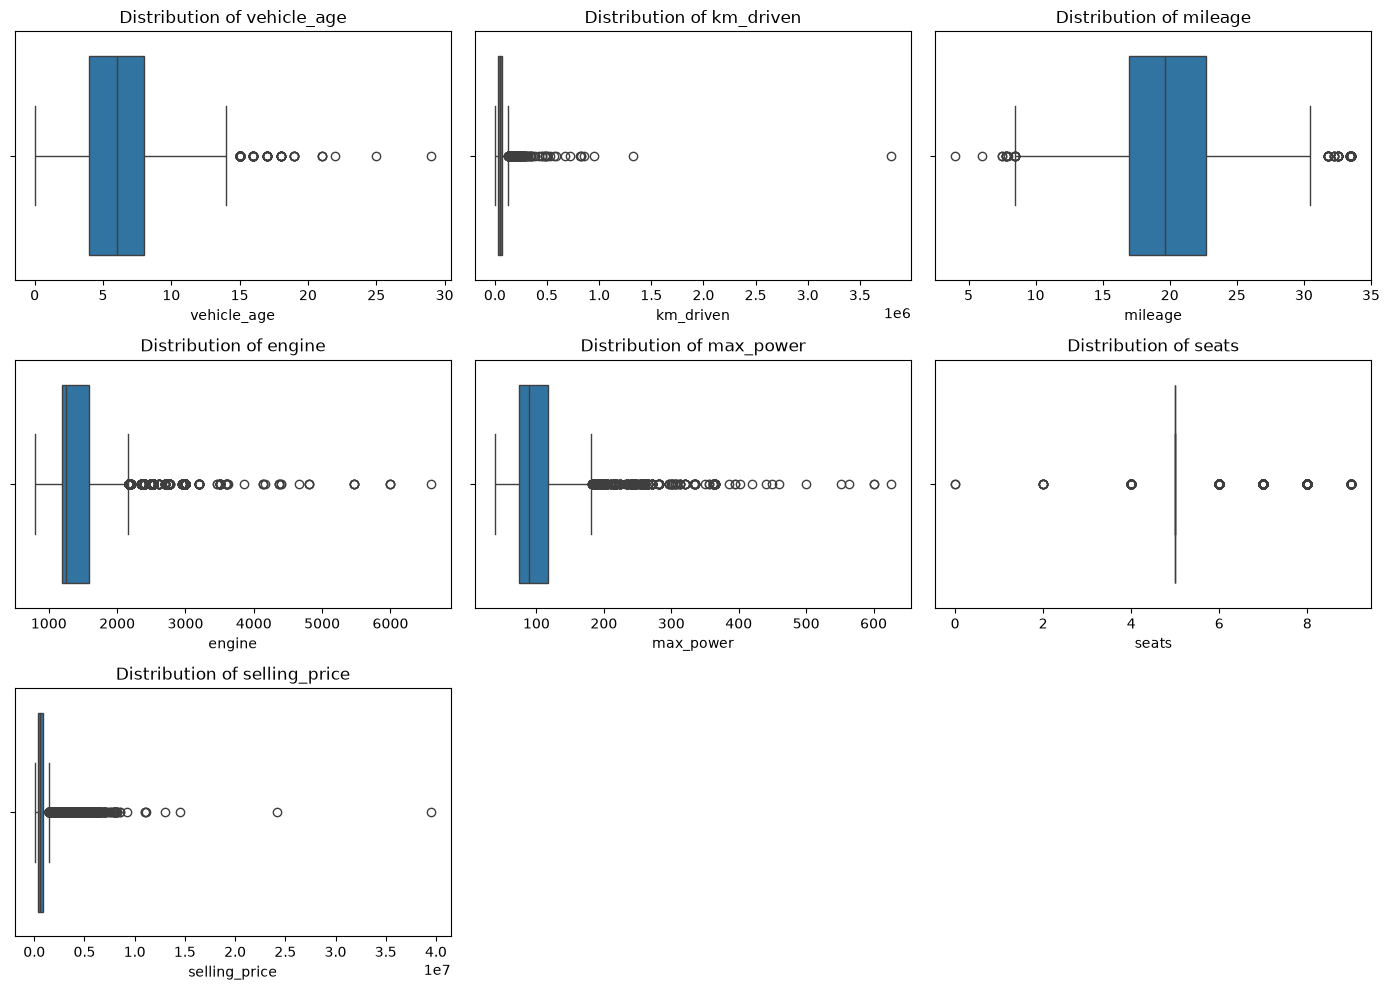

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# List of numerical columns to inspect
numerical_columns = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

# Set up the matplotlib figure
plt.figure(figsize=(14, 10))

# Generate boxplots for each numerical feature to visualize outliers
for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=data[column])
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()


In [4]:
# Removing the Outliers

def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

# Apply the function to the columns with potential outliers
columns_with_outliers = ['km_driven', 'mileage', 'engine', 'max_power']

for column in columns_with_outliers:
    data = remove_outliers_iqr(data, column)

# Save the cleaned dataset to a new file (optional)
data.to_csv(DATA_DIR / "cleaned_cardekho_dataset.csv", index=False)

# Check the shape of the dataset after outlier removal
print(data.shape)


(12092, 13)


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score
import joblib

# Load your cleaned dataset
data = pd.read_csv(DATA_DIR / "cleaned_cardekho_dataset.csv")

# Define features and target variable
X = data.drop(columns=['selling_price', 'car_name', 'model'])  # Drop 'selling_price' and irrelevant columns
y = data['selling_price']

# List of categorical and numerical columns
categorical_cols = ['brand', 'seller_type', 'fuel_type', 'transmission_type']
numerical_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

# Preprocessing for numerical data
numerical_transformer = StandardScaler()

# Preprocessing for categorical data
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Bundle preprocessing for numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)])

# Define the model
model = ExtraTreesRegressor(random_state=42)

# Create and combine preprocessing and modeling pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('model', model)])

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [6]:
sample_data = data.head(10)

# Display the features (a) and corresponding labels (b)
a = sample_data.drop(columns=['selling_price'])
b = sample_data['selling_price']

# combine a and b for display
display(pd.concat([a,b], axis=1))

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000
5,Maruti Wagon R,Maruti,Wagon R,8,35000,Individual,Petrol,Manual,18.90,998,67.10,5,350000
6,Hyundai i10,Hyundai,i10,8,40000,Dealer,Petrol,Manual,20.36,1197,78.90,5,315000
7,Maruti Wagon R,Maruti,Wagon R,3,17512,Dealer,Petrol,Manual,20.51,998,67.04,5,410000
8,Hyundai Venue,Hyundai,Venue,2,20000,Individual,Petrol,Automatic,18.15,998,118.35,5,1050000
9,Maruti Swift,Maruti,Swift,4,28321,Dealer,Petrol,Manual,16.60,1197,85.00,5,511000


In [7]:
# Define the parameter grid for GridSearchCV
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

# Apply GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, verbose=2, scoring='neg_mean_absolute_error')
grid_search.fit(X_train, y_train)

# Get the best model
best_model = grid_search.best_estimator_



Fitting 5 folds for each of 108 candidates, totalling 540 fits


In [8]:
# Perform k-fold cross-validation
cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
print("Cross-validation MAE scores:", -cv_scores)
print("Mean CV MAE score:", -cv_scores.mean())

# Evaluate the model on the test set
y_pred = best_model.predict(X_test)
test_mae = abs(y_pred - y_test).mean()
print("Test MAE:", test_mae)



Cross-validation MAE scores: [60644.15752361 61907.97338072 60643.58407849 61722.94056192
 61079.95901717]
Mean CV MAE score: 61199.722912383884
Test MAE: 61715.7334055205


In [9]:
from sklearn.metrics import r2_score

# Predict on the test set
y_pred = best_model.predict(X_test)

# Calculate R-squared (R²) score
r2 = r2_score(y_test, y_pred)
print("R-squared (R²):", r2)


R-squared (R²): 0.8821581759654257


In [10]:
# Calculate percentage of predictions within 10% of actual values
tolerance = 0.1
accuracy_within_tolerance = (abs(y_pred - y_test) <= tolerance * y_test).mean()

print(f"Accuracy within 10% tolerance: {accuracy_within_tolerance * 100:.2f}%")


Accuracy within 10% tolerance: 51.47%


In [11]:
# Save the model to a file using joblib
joblib.dump(best_model, MODEL_DIR / "car_price_prediction_model.pkl")
print("Model saved successfully.")
print("Model saved successfully.")


Model saved successfully.
Model saved successfully.
